# Atividade: Avaliação Textual e Visualização do WikiText-2

**Dataset:** [WikiText-2](https://huggingface.co/datasets/Salesforce/wikitext) (Salesforce / Hugging Face)

Este notebook cobre só o **download** e a **formatação** dos dados. A análise (Etapas 1–4) começa a partir do arquivo salvo no final.

### Sobre a configuração escolhida
O WikiText-2 tem duas versões no Hugging Face:

| Configuração | Conteúdo |
|---|---|
| `wikitext-2-raw-v1` | texto original (maiúsculas, pontuação e palavras raras preservadas) |
| `wikitext-2-v1` | versão tokenizada: palavras fora do vocabulário (~33k) viram `<unk>` |

Usamos a **raw**, porque métricas de diversidade lexical (TTR, MTLD, Distinct-N) ficariam distorcidas com `<unk>`.

### Formato das linhas
Cada registro do dataset é **uma linha** de texto, não um artigo:
- `= Título =` → início de um artigo
- `= = Seção = =`, `= = = Subseção = = =` → cabeçalhos internos
- linhas vazias → separadores entre parágrafos/seções
- o texto vem pré-tokenizado, com separadores como `@-@`, `@,@` e `@.@` (ex.: `1 @,@ 000`, `well @-@ known`)

Imports e caminhos.

In [1]:
from pathlib import Path

import pandas as pd
from datasets import load_dataset

DATASET_ID = "Salesforce/wikitext"
CONFIG = "wikitext-2-raw-v1"

DATA_DIR = Path("data")
CACHE_DIR = DATA_DIR / "hf_cache"
OUTPUT_FILE = DATA_DIR / "wikitext2_raw.parquet"

DATA_DIR.mkdir(exist_ok=True)

Download do WikiText-2 (raw).

In [2]:
ds = load_dataset(DATASET_ID, CONFIG, cache_dir=str(CACHE_DIR))
ds

DatasetDict({
    test: Dataset({
        features: ['text'],
        num_rows: 4358
    })
    train: Dataset({
        features: ['text'],
        num_rows: 36718
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 3760
    })
})

Linhas como vieram do dataset.

In [3]:
for line in ds["train"]["text"][:12]:
    print(repr(line))

''
' = Valkyria Chronicles III = \n'
''
' Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . Employing the same fusion of tactical and real @-@ time gameplay as its predecessors , the story runs parallel to the first game and follows the " Nameless " , a penal military unit serving the nation of Gallia during the Second Europan War who perform secret black operations and are pitted against the Imperial unit " Calamaty Raven " . \n'
" The game began development in 2010 , carrying over a large portion of the work done on Valkyria Chronicles II . While it retained the standard features of the series , it also underwent multiple adjustments , such as making the game more forgiving 

Junta os splits num DataFrame: `split`, `line_id`, `text`.

In [4]:
frames = []
for split in ["train", "validation", "test"]:
    part = ds[split].to_pandas()
    part["text"] = part["text"].str.strip()
    part.insert(0, "split", split)
    part.insert(1, "line_id", range(len(part)))
    frames.append(part)

df = pd.concat(frames, ignore_index=True)
df["split"] = pd.Categorical(df["split"], categories=["train", "validation", "test"])

df.info()
df.groupby("split", observed=True).size().rename("linhas")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44836 entries, 0 to 44835
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   split    44836 non-null  category
 1   line_id  44836 non-null  int64   
 2   text     44836 non-null  object  
dtypes: category(1), int64(1), object(1)
memory usage: 744.6+ KB


split
train         36718
validation     3760
test           4358
Name: linhas, dtype: int64

In [5]:
df.head(15)

,split,line_id,text
0,train,0,
1,train,1,= Valkyria Chronicles III =
2,train,2,
3,train,3,Senjō no Valkyria 3 : Unrecorded Chronicles ( ...
4,train,4,"The game began development in 2010 , carrying ..."
5,train,5,"It met with positive sales in Japan , and was ..."
6,train,6,
7,train,7,= = Gameplay = =
8,train,8,
9,train,9,"As with previous Valkyira Chronicles games , V..."


Salvando.

In [6]:
df.to_parquet(OUTPUT_FILE, index=False)
print(f"salvo em {OUTPUT_FILE.resolve()}  ({OUTPUT_FILE.stat().st_size / 1e6:.1f} MB)")

salvo em C:\Users\jairo\AppData\Local\Temp\claude\00aa4b6cad416de3\5dc6d18b-0b46-483c-ad59-779389a6954f\scratchpad\data\wikitext2_raw.parquet  (7.8 MB)


Pega o nível (`level`, quantidade de `=`) e o título (`title`) das linhas de cabeçalho. Só conta como título se tiver linha vazia antes e depois, porque às vezes aparece `=` no meio de legendas e equações.

In [7]:
df = df.join(
    df["text"]
    .str.extract(r"^(=(?: =)*) (.+) \1$")
    .rename(columns={0: "level", 1: "title"})
    .assign(level=lambda x: x["level"].str.count("=").astype("Int64"))
)

# só é cabeçalho se tiver linha vazia antes e depois
vizinhas = df.groupby("split", observed=True)["text"]
cercado = vizinhas.shift(1).fillna("").eq("") & vizinhas.shift(-1).fillna("").eq("")
df.loc[~cercado, ["level", "title"]] = pd.NA

Marca em cada linha a qual artigo, seção e subseção ela pertence (níveis 3 a 5).

In [8]:
def rotulo(df, k):
    s = df["title"].where(df["level"] == k)                    # 1. só os títulos do nível k
    s = s.mask((df["level"] < k).fillna(False), "")            # 2. reset ("") quando aparece um nível acima
    s = s.groupby(df["split"], observed=True).ffill()          # 3. propaga para baixo, dentro do split
    return s.replace("", pd.NA)                                # 4. reset vira vazio de verdade

niveis = pd.concat({k: rotulo(df, k) for k in range(1, 6)}, axis=1)   # uma coluna por nível (1 a 5)

df["artigo"]    = niveis[1]
df["artigo_id"] = df["level"].eq(1).fillna(False).groupby(df["split"], observed=True).cumsum()
df["secao"]     = niveis[2].fillna("(introdução)").where(niveis[1].notna())

# subseção = caminho dos níveis 3 a 5 (ex.: "Music > Soundtrack")
sub = niveis[[3, 4, 5]]
df["subsecao"] = sub.stack().groupby(level=0).agg(" > ".join).reindex(df.index).fillna("-")
df["subsecao_nivel"] = sub.notna().mul([3, 4, 5]).max(axis=1).replace(0, pd.NA).astype("Int64")

Limpeza do texto: junta os `@-@`, `@,@` e `@.@` (`well @-@ known` vira `well-known`), cola a pontuação e as contrações (`Japan , it 's` vira `Japan, it's`) e tira o `\ufeff` e os `( )` vazios. Também vale para os títulos. A coluna `text` continua original, e as tabelas `artigos` e `secoes` usam a `text_limpo`.

In [9]:
def limpar(s):
    return (
        s
        .str.replace(r" @(.)@(?: |$)", r"\1", regex=True)                       # well @-@ known → well-known, 1 @,@ 000 → 1,000
        .str.replace("\ufeff", "")
        .str.replace(r"\(\s*\)", "", regex=True)                                # ( ) vazios
        .str.replace(r" ([,.;:!?%)\]])", r"\1", regex=True)                     # Japan , it → Japan, it
        .str.replace(r"([(\[]) ", r"\1", regex=True)                            # ( Japanese → (Japanese
        .str.replace(r"(\w) '(\w)", r"\1'\2", regex=True)                       # it 's → it's, don 't → don't, O 'Brien → O'Brien
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

df["text_limpo"] = limpar(df["text"])
for col in ["artigo", "secao", "subsecao"]:                                     # títulos também: "M @-@ 122 ( Michigan highway )"
    df[col] = limpar(df[col])

df = df[df["text_limpo"] != ""].reset_index(drop=True)
paragrafos = df[df["level"].isna()]

artigos = (
    paragrafos
    .groupby(["split", "artigo_id", "artigo"], observed=True, sort=False)["text_limpo"]
    .agg("\n".join)
    .reset_index()
)
artigos

,split,artigo_id,artigo,text_limpo
0,train,1,Valkyria Chronicles III,Senjō no Valkyria 3: Unrecorded Chronicles (Ja...
1,train,2,Tower Building of the Little Rock Arsenal,"The Tower Building of the Little Rock Arsenal,..."
2,train,3,Cicely Mary Barker,Cicely Mary Barker (28 June 1895 – 16 February...
3,train,4,Gambia women's national football team,The Gambia women's national football team repr...
4,train,5,Plain maskray,The plain maskray or brown stingray (Neotrygon...
...,...,...,...,...
715,test,56,Tatwine,Tatwine or Tatwin (Tatuini or Tadwinus; c. 670...
716,test,57,German Type UB I submarine,The Type UB I was a class of small coastal sub...
717,test,58,Military history of Gibraltar during World War II,The military history of Gibraltar during World...
718,test,59,Nerva,Nerva (Latin: Marcus Cocceius Nerva Caesar Aug...


In [10]:
secoes = (
    paragrafos
    .groupby(["split", "artigo_id", "artigo", "secao"], observed=True, sort=False)["text_limpo"]
    .agg("\n".join)
    .reset_index()
)
secoes

,split,artigo_id,artigo,secao,text_limpo
0,train,1,Valkyria Chronicles III,(introdução),Senjō no Valkyria 3: Unrecorded Chronicles (Ja...
1,train,1,Valkyria Chronicles III,Gameplay,"As with previous Valkyira Chronicles games, Va..."
2,train,1,Valkyria Chronicles III,Plot,The game takes place during the Second Europan...
3,train,1,Valkyria Chronicles III,Development,Concept work for Valkyria Chronicles III began...
4,train,1,Valkyria Chronicles III,Reception,"On its day of release in Japan, Valkyria Chron..."
...,...,...,...,...,...
4045,test,60,The Hustler (film),Cast,Cast notes\nPool champion Willie Mosconi has a...
4046,test,60,The Hustler (film),Production,The Tevis novel had been optioned several time...
4047,test,60,The Hustler (film),Themes,The Hustler is fundamentally a story of what i...
4048,test,60,The Hustler (film),Reception,The Hustler had its world premiere in Washingt...


In [11]:
df.head(50)

,split,line_id,text,level,title,artigo,artigo_id,secao,subsecao,subsecao_nivel,text_limpo
0,train,1,= Valkyria Chronicles III =,1,Valkyria Chronicles III,Valkyria Chronicles III,1,(introdução),-,<NA>,= Valkyria Chronicles III =
1,train,3,Senjō no Valkyria 3 : Unrecorded Chronicles ( ...,<NA>,<NA>,Valkyria Chronicles III,1,(introdução),-,<NA>,Senjō no Valkyria 3: Unrecorded Chronicles (Ja...
2,train,4,"The game began development in 2010 , carrying ...",<NA>,<NA>,Valkyria Chronicles III,1,(introdução),-,<NA>,"The game began development in 2010, carrying o..."
3,train,5,"It met with positive sales in Japan , and was ...",<NA>,<NA>,Valkyria Chronicles III,1,(introdução),-,<NA>,"It met with positive sales in Japan, and was p..."
4,train,7,= = Gameplay = =,2,Gameplay,Valkyria Chronicles III,1,Gameplay,-,<NA>,= = Gameplay = =
5,train,9,"As with previous Valkyira Chronicles games , V...",<NA>,<NA>,Valkyria Chronicles III,1,Gameplay,-,<NA>,"As with previous Valkyira Chronicles games, Va..."
6,train,10,"The game 's battle system , the BliTZ system ,...",<NA>,<NA>,Valkyria Chronicles III,1,Gameplay,-,<NA>,"The game's battle system, the BliTZ system, is..."
7,train,11,Troops are divided into five classes : Scouts ...,<NA>,<NA>,Valkyria Chronicles III,1,Gameplay,-,<NA>,"Troops are divided into five classes: Scouts, ..."
8,train,13,= = Plot = =,2,Plot,Valkyria Chronicles III,1,Plot,-,<NA>,= = Plot = =
9,train,15,The game takes place during the Second Europan...,<NA>,<NA>,Valkyria Chronicles III,1,Plot,-,<NA>,The game takes place during the Second Europan...


## Etapa 1 · Distribuição de palavras, frases e artigos

Imports dos gráficos, cores por split e o padrão de palavra 


In [12]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from nltk.tokenize.punkt import PunktTokenizer

sns.set_theme(style="whitegrid", rc={
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#666666", "grid.color": "#e6e6e6",
    "axes.labelcolor": "#191919", "xtick.color": "#666666", "ytick.color": "#666666",
})
CORES = {"train": "#257de0", "validation": "#f47230", "test": "#00b894"}
AZUL = CORES["train"]

PALAVRA = r"\w+(?:[-.,']\w+)*"

Tabela de frases. Primeiro separei os parágrafos em `prosa` e `lista`: se tem até 12 palavras e não termina com `.`, `!` ou `?`, considerei item de lista, tabela, legenda ou crédito (ex.: `Studio albums`, `Cindy Mizelle - background vocals`). Para dividir as frases usei o punkt com algumas abreviações a mais (`No.`, `Op.`, `ca.`, `U.S.`), porque sem elas ele cortava frases no meio. As estatísticas de frases usam só a `prosa`, mas as palavras das listas continuam contando nos totais.

In [13]:
tok = PunktTokenizer("english")
tok._params.abbrev_types.update({"no", "nos", "op", "ed", "eds", "ca", "vol", "lit", "pp", "fig", "u.s", "u.k", "st", "jr", "sr"})   # No. 5, Op. 28, born ca. 1940

pars = (
    secoes
    .assign(paragrafo=secoes["text_limpo"].str.split("\n"))     # 1 linha = 1 parágrafo
    .explode("paragrafo")
    .drop(columns="text_limpo")
    .reset_index(drop=True)
)
curto = pars["paragrafo"].str.count(PALAVRA) <= 12
sem_ponto = ~pars["paragrafo"].str.contains(r"""[.!?]\s*["')\]]*$""")
pars["tipo"] = "prosa"
pars.loc[curto & sem_ponto, "tipo"] = "lista"

frases = (
    pars
    .assign(frase=pars["paragrafo"].map(tok.tokenize))
    .explode("frase")
    .drop(columns="paragrafo")
    .reset_index(drop=True)
)
frases["n_palavras"] = frases["frase"].str.count(PALAVRA)
frases = frases[frases["n_palavras"] > 0].reset_index(drop=True)   # tira "frases" só de pontuação
prosa = frases[frases["tipo"] == "prosa"]                          # frases de verdade

print(pars["tipo"].value_counts(normalize=True).round(3).to_dict())
frases

{'prosa': 0.893, 'lista': 0.107}


,split,artigo_id,artigo,secao,tipo,frase,n_palavras
0,train,1,Valkyria Chronicles III,(introdução),prosa,Senjō no Valkyria 3: Unrecorded Chronicles (Ja...,38
1,train,1,Valkyria Chronicles III,(introdução),prosa,"Released in January 2011 in Japan, it is the t...",15
2,train,1,Valkyria Chronicles III,(introdução),prosa,Employing the same fusion of tactical and real...,52
3,train,1,Valkyria Chronicles III,(introdução),prosa,"The game began development in 2010, carrying o...",19
4,train,1,Valkyria Chronicles III,(introdução),prosa,While it retained the standard features of the...,24
...,...,...,...,...,...,...,...
94243,test,60,The Hustler (film),Legacy,prosa,Perhaps the greatest beneficiary of the film's...,16
94244,test,60,The Hustler (film),Legacy,prosa,Mosconi claimed in an interview at the time of...,32
94245,test,60,The Hustler (film),Legacy,prosa,Wanderone immediately adopted the Minnesota Fa...,22
94246,test,60,The Hustler (film),Legacy,prosa,Author Walter Tevis denied for the rest of his...,22


Contagens por seção e por artigo. `n_frases` e `palavras_por_frase` usam só prosa.

In [14]:
chave = ["split", "artigo_id"]

secoes["n_palavras"] = secoes["text_limpo"].str.count(PALAVRA)
secoes["n_frases"] = prosa.groupby(chave + ["secao"], observed=True).size().reindex(
    pd.MultiIndex.from_frame(secoes[chave + ["secao"]])).fillna(0).astype(int).to_numpy()

contagens = (
    prosa.groupby(chave, observed=True)
    .agg(n_frases=("frase", "size"), palavras_por_frase=("n_palavras", "mean"))
    .join(secoes.groupby(chave, observed=True).size().rename("n_secoes"))
)
artigos = artigos.drop(columns=["n_palavras", "n_frases", "n_secoes", "palavras_por_frase"], errors="ignore")
artigos["n_palavras"] = artigos["text_limpo"].str.count(PALAVRA)
artigos = artigos.merge(contagens, on=chave, how="left")

artigos.drop(columns="text_limpo").head()

,split,artigo_id,artigo,n_palavras,n_frases,palavras_por_frase,n_secoes
0,train,1,Valkyria Chronicles III,3222,135,23.866667,6
1,train,2,Tower Building of the Little Rock Arsenal,3364,137,23.824818,6
2,train,3,Cicely Mary Barker,2391,103,19.038835,4
3,train,4,Gambia women's national football team,548,31,17.677419,3
4,train,5,Plain maskray,1069,54,19.796296,6


Resumo por split (frases contando só prosa).

In [15]:
totais = artigos.groupby("split", observed=True).agg(
    artigos=("artigo_id", "size"),
    secoes=("n_secoes", "sum"),
    frases=("n_frases", "sum"),
    palavras=("n_palavras", "sum"),
)
totais.loc["total"] = totais.sum()
totais

,artigos,secoes,frases,palavras
split,,,,
train,600,3358,74876,1697200
validation,60,345,7937,177909
test,60,347,9029,200105
total,720,4050,91842,2075214


In [16]:
metricas = ["n_palavras", "n_frases", "n_secoes", "palavras_por_frase"]
(artigos.groupby("split", observed=True)[metricas]
 .agg(["mean", "median", "std", "min", "max"])
 .round(1)
 .T)

split                        train  validation     test
n_palavras         mean     2828.7      2965.2   3335.1
                   median   1992.0      2253.0   2199.0
                   std      2221.6      2520.1   2746.3
                   min       226.0       617.0    385.0
                   max     14259.0     16088.0  11636.0
n_frases           mean      124.8       132.3    150.5
                   median     89.5        96.0     92.0
                   std        97.4       108.9    127.5
                   min        12.0        31.0     17.0
                   max       663.0       637.0    506.0
n_secoes           mean        5.6         5.8      5.8
                   median      5.0         5.0      5.0
                   std         2.2         2.3      2.4
                   min         2.0         3.0      2.0
                   max        17.0        12.0     14.0
palavras_por_frase mean       22.5        22.5     22.2
                   median     22.3        22.4     22.2
                   std         2.9         3.2      2.7
                   min        13.9        15.7     17.0
                   max        37.0        30.6     31.4

**Gráfico 1** · Artigos e palavras por split

O gráfico mostra como o dataset foi dividido. Em número de artigos a divisão é 600 / 60 / 60 (83% / 8% / 8%), mas em palavras validation e test ficam com ~9% e ~10%, porque os artigos deles são um pouco maiores em média. Então faz mais sentido medir o tamanho de cada split em palavras do que em artigos.

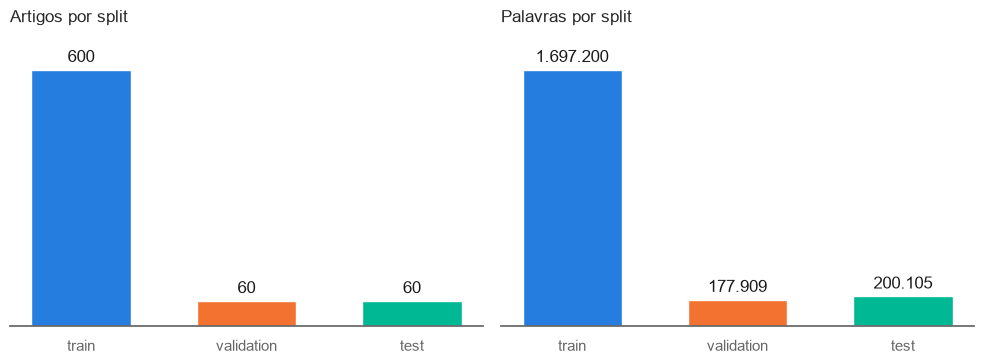

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, col, titulo in [(axes[0], "artigos", "Artigos por split"), (axes[1], "palavras", "Palavras por split")]:
    v = totais.loc[list(CORES), col]
    barras = ax.bar(v.index, v.values, color=list(CORES.values()), width=0.6)
    ax.bar_label(barras, labels=[f"{x:,.0f}".replace(",", ".") for x in v.values], padding=3, color="#191919")
    ax.set_title(titulo, loc="left", pad=12)
    ax.set_ylim(0, v.max() * 1.12)
    ax.set_yticks([])
    ax.grid(False)
    ax.spines["left"].set_visible(False)
plt.tight_layout()
plt.show()

**Gráfico 2** · Distribuição de palavras por artigo

Cada barra é uma faixa de tamanho e a altura é a quantidade de artigos nessa faixa. A distribuição é assimétrica à direita: a maioria dos artigos tem entre 1 e 3 mil palavras, mas alguns são bem longos (até ~16 mil) e puxam a média (2.882) para cima da mediana (2.044). Por isso a mediana representa melhor um artigo típico.

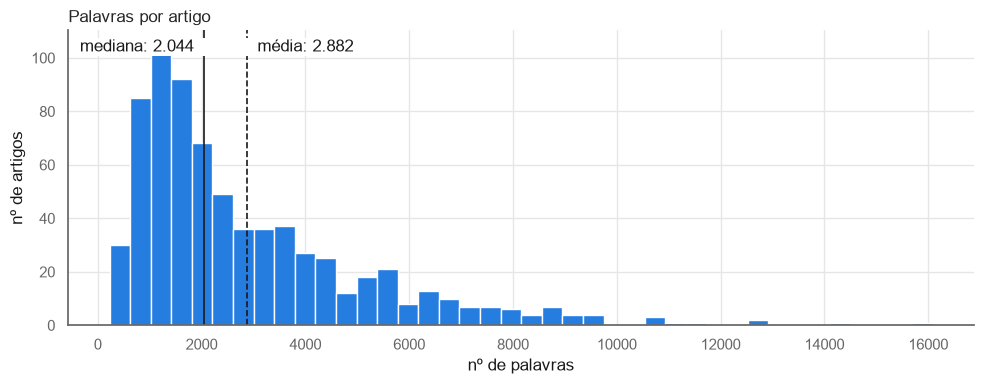

In [18]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(artigos["n_palavras"], bins=40, color=AZUL, edgecolor="white", linewidth=1)
topo = ax.get_ylim()[1]
for valor, nome, estilo, ha in [(artigos["n_palavras"].median(), "mediana", "-", "right"),
                                (artigos["n_palavras"].mean(), "média", "--", "left")]:
    ax.axvline(valor, color="#191919", linestyle=estilo, linewidth=1.2)
    ax.text(valor, topo * 0.97, f"  {nome}: {valor:,.0f}  ".replace(",", "."), color="#191919", va="top", ha=ha,
            bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax.set(xlabel="nº de palavras", ylabel="nº de artigos")
ax.set_title("Palavras por artigo", loc="left")
plt.tight_layout()
plt.show()

**Gráfico 3** · Frases por artigo e palavras por frase

Na esquerda, as frases por artigo têm o mesmo formato do gráfico anterior, já que artigo maior tem mais frases. Na direita (só prosa), o tamanho das frases tem formato de sino, com centro em ~21 palavras. Depois de separar as listas e arrumar as abreviações, as frases com 1 a 5 palavras caíram de 3.529 (3,7%) para 1.688 (1,8%). As que sobraram são frases curtas de verdade (`Stanley immediately goes home.`) ou referências (`Hooglund, Eric.`). A última barra junta o 1% de frases mais longas (55 palavras ou mais).

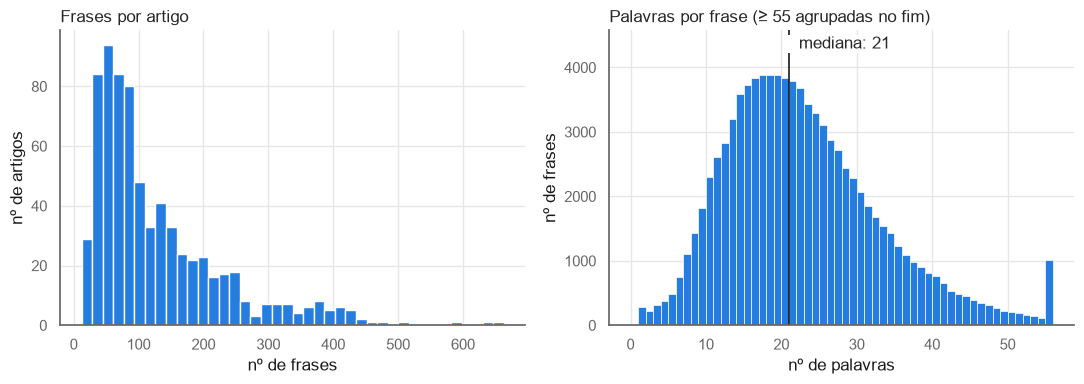

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(artigos["n_frases"], bins=40, color=AZUL, edgecolor="white", linewidth=1)
axes[0].set(xlabel="nº de frases", ylabel="nº de artigos")
axes[0].set_title("Frases por artigo", loc="left")

limite = prosa["n_palavras"].quantile(0.99)   # agrupa o 1% mais longo na última barra
mediana = prosa["n_palavras"].median()
axes[1].hist(prosa["n_palavras"].clip(upper=limite), bins=range(0, int(limite) + 2), color=AZUL, edgecolor="white", linewidth=0.5)
axes[1].axvline(mediana, color="#191919", linewidth=1.2)
axes[1].set_ylim(0, axes[1].get_ylim()[1] * 1.12)
axes[1].text(mediana, axes[1].get_ylim()[1] * 0.98, f"  mediana: {mediana:.0f}", va="top",
             bbox=dict(facecolor="white", edgecolor="none", pad=1))
axes[1].set(xlabel="nº de palavras", ylabel="nº de frases")
axes[1].set_title(f"Palavras por frase (≥ {limite:.0f} agrupadas no fim)", loc="left")

plt.tight_layout()
plt.show()

**Frases longas** · o que tem na última barra do Gráfico 3 (55 palavras ou mais, ~1% da prosa)

Olhando essas frases, a maioria é longa de verdade (estilo de enciclopédia) e não erro do tokenizador. Aparecem principalmente:
- frases com várias orações ligadas por `;`
- listas dentro do texto (características, filmes, prêmios separados por `,` ou `;`), que são as maiores, com até 180 palavras
- citações longas entre aspas (críticas de filmes e músicas)
- alguns erros do punkt, quando letras soltas parecem iniciais (`... I U R R. The next day`) e ele não corta a frase

Como é texto real, mantive na análise.

In [20]:
longas = prosa[prosa["n_palavras"] >= limite]
print(f"{len(longas)} frases com ≥ {limite:.0f} palavras ({len(longas) / len(prosa):.1%} da prosa) · "
      f"mediana {longas['n_palavras'].median():.0f} · {longas['frase'].str.contains(';').mean():.0%} usam ';'")

cols = ["artigo", "secao", "n_palavras", "frase"]
with pd.option_context("display.max_colwidth", 300):
    display(longas.nlargest(3, "n_palavras")[cols],        # as maiores: enumerações
            longas.sample(5, random_state=5)[cols])         # amostra: compostas e citações

1012 frases com ≥ 55 palavras (1.1% da prosa) · mediana 61 · 30% usam ';'


,artigo,secao,n_palavras,frase
69614,Corythosaurus,Description,180,"In 1916, Brown expanded the character set to include more features; in the revised version: a comparatively short skull with a high helmet-like crest formed by nasals, prefrontals and frontals; the nasals not being separated in front by premaxillaries; a narrow beak, expanded section in front of..."
77058,Shikamaru Nara,Appearances,171,"Besides the Naruto anime and manga, Shikamaru is featured in seven of the featured films in the series: in the second film, he aids Naruto Uzumaki and Sakura Haruno in fighting against Haido, a utopian idealist seeking to rule the world with a power called Gelel; in the fourth, Shikamaru appears..."
74214,"Youth on the Prow, and Pleasure at the Helm",Reception,118,"The Library of the Fine Arts felt "" in classical design, anatomical drawing, elegance of attitude, fineness of form, and gracefulness of grouping, no doubt Mr. Etty has no superior "", and while "" the representation of the ideas in the lines quoted [from The Bard] are beautifully and accurately e..."


,artigo,secao,n_palavras,frase
16352,2010 Haiti earthquake,Early response,55,"The Canadian government worked to expedite around 100 adoption cases that were already underway when the earthquake struck, issuing temporary permits and waiving regular processing fees; the federal government also announced that it would cover adopted children's healthcare costs upon their arri..."
46477,G.I. Joe: Retaliation,Reception,74,"Owen Gleiberman of Entertainment Weekly gave the film a grade of "" B- "", calling it "" well-executed technocratic action fluff "" and commented: "" In its dehumanized and trivial way, it's a triumph of razor-sharp, hyper-violent style over formulaic substance... Hollywood has now evolved to the poi..."
77709,Angel of Death (Slayer song),Appearances,70,""" Angel of Death "" has appeared in several movies and TV shows including Gremlins 2: The New Batch in a scene when the gremlin Mohawk is turning into a spider, Jackass: The Movie during a car stunt, the 2005 Iraq War documentary Soundtrack to War, which details the role of music on the contempor..."
55831,Road to the North Pole,Cultural references,57,"Continuing with the song, Jillian Russell wishes for Easter eggs, Joe wishes for one day when kids don't stare at him, Bonnie wants platinum-plated silverware, Quagmire wants "" Japanese girls of no restraint "" to choke him and then whip him and Mort (who is Jewish) says he will sue if they put a..."
1280,Ancient Egyptian deities,Characteristics,68,"The eight gods of the Ogdoad, who represent the chaos that precedes creation, give birth to the sun god, who establishes order in the newly formed world; Ptah, who embodies thought and creativity, gives form to all things by envisioning and naming them; Atum produces all things as emanations of ..."


**Gráfico 4** · Os splits têm o mesmo perfil?

No boxplot, a caixa vai do 1º ao 3º quartil, a linha do meio é a mediana, as hastes mostram o resto da faixa normal e os pontos são outliers. Na esquerda, as medianas dos três splits são parecidas (entre ~2.000 e 2.250 palavras por artigo), mas o test tem a caixa mais alta, então tem mais artigos longos. Na direita, o tamanho das frases é praticamente igual nos três. Ou seja, validation e test representam bem o train em tamanho de texto, com alguma variação por terem só 60 artigos cada.

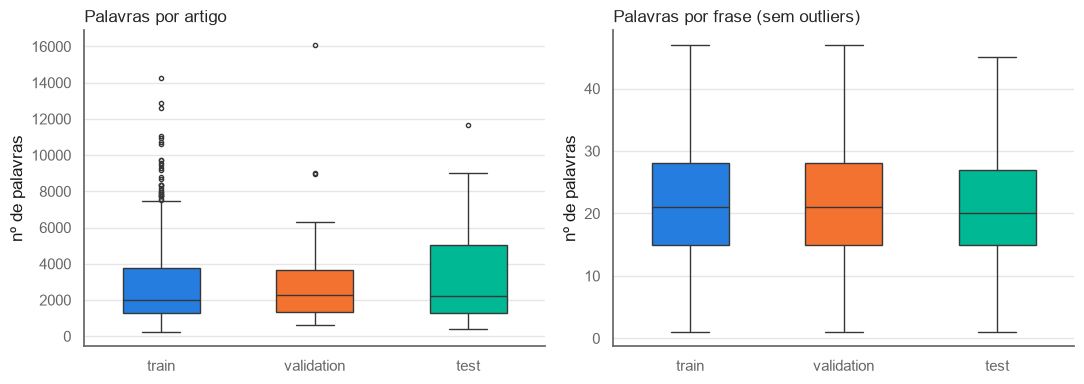

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=artigos, x="split", y="n_palavras", hue="split", palette=CORES, legend=False, ax=axes[0],
            width=0.5, fliersize=3, saturation=1)
sns.boxplot(data=prosa, x="split", y="n_palavras", hue="split", palette=CORES, legend=False, ax=axes[1],
            width=0.5, showfliers=False, saturation=1)
axes[0].set(xlabel="", ylabel="nº de palavras")
axes[0].set_title("Palavras por artigo", loc="left")
axes[1].set(xlabel="", ylabel="nº de palavras")
axes[1].set_title("Palavras por frase (sem outliers)", loc="left")
plt.tight_layout()
plt.show()

## Etapa 1.2 · Frequência das palavras e vocabulário

Tabela com uma linha por palavra (mesmo padrão `PALAVRA` da Etapa 1), com a coluna `palavra` em minúsculas. Tokens é o total de palavras, types são as palavras diferentes (o vocabulário) e `types_maiusc` são os types sem passar para minúsculas.

In [22]:
palavras = (
    artigos[["split", "artigo_id"]]
    .assign(original=artigos["text_limpo"].str.findall(PALAVRA))
    .explode("original")
    .reset_index(drop=True)
)
palavras["palavra"] = palavras["original"].str.lower()
freq = palavras["palavra"].value_counts()

resumo = palavras.groupby("split", observed=True).agg(
    tokens=("palavra", "size"), types=("palavra", "nunique"), types_maiusc=("original", "nunique"))
resumo.loc["total"] = [len(palavras), palavras["palavra"].nunique(), palavras["original"].nunique()]
resumo["ttr"] = (resumo["types"] / resumo["tokens"]).round(3)
resumo

,tokens,types,types_maiusc,ttr
split,,,,
train,1697200,78622,88368,0.046
validation,177909,19144,21320,0.108
test,200105,20547,22689,0.103
total,2075214,87772,98712,0.042


São ~88 mil types em ~2,08 milhões de tokens. Sem passar para minúsculas seriam ~99 mil (12% a mais), porque `The`/`the` ou `War`/`war` contariam como palavras diferentes. O TTR (types / tokens) do train (0,046) é bem menor que o de validation e test (~0,1), mas isso não quer dizer que o train é menos variado. O TTR sempre cai quando o texto cresce, porque as palavras comuns vão se repetindo e as novas aparecem cada vez menos. Então o TTR só serve para comparar textos de tamanho parecido.

**Gráfico 5** · Train × test: as mesmas palavras com a mesma frequência?

Na esquerda, cada ponto é uma palavra que aparece nos dois splits, com a frequência por milhão de tokens no train (x) e no test (y). Se o ponto está na diagonal, a palavra tem a mesma frequência nos dois. As stopwords (em laranja) ficam praticamente em cima da diagonal, porque a gramática é a mesma em qualquer artigo. As outras palavras se espalham mais (correlação de 0,73 em escala log), principalmente embaixo, onde a palavra aparece poucas vezes e qualquer ocorrência a mais muda muito a taxa (as linhas horizontais são palavras que aparecem 1, 2, 3... vezes no test). Na direita estão as palavras mais desbalanceadas, e todas são nomes ou assuntos de artigos: o test tem artigos sobre Brock Lesnar, Bintulu, temnospondyls e Nero, e o train sobre Federer, Scientology e xenônio. Então a diferença entre os splits é de assunto, não de linguagem, e no test o modelo vai encontrar palavras que viu pouco ou nunca no treino.

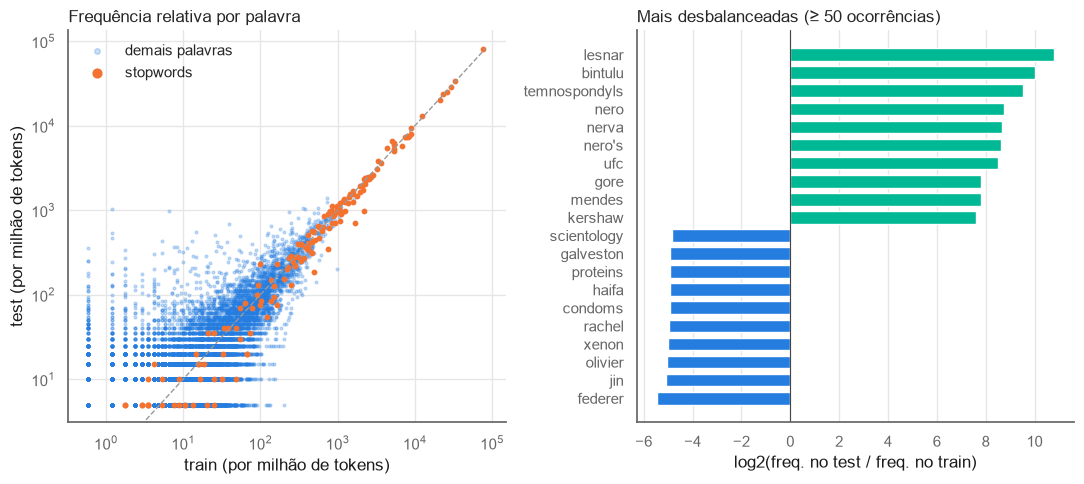

15,493 palavras aparecem nos dois splits · correlação (log) = 0.73


In [23]:
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))
cont = palavras.groupby("split", observed=True)["palavra"].value_counts().unstack(0, fill_value=0)
por_milhao = cont / cont.sum() * 1e6
pm = por_milhao[(cont["train"] > 0) & (cont["test"] > 0)]   # só palavras presentes nos dois
e_stop = pm.index.isin(STOP)

suav = (cont + 1) / (cont + 1).sum()                           # +1 para não dividir por zero quando falta num split
razao = np.log2(suav["test"] / suav["train"])[(cont["train"] + cont["test"]) >= 50]
extremos = pd.concat([razao.nsmallest(10), razao.nlargest(10)]).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].scatter(pm.loc[~e_stop, "train"], pm.loc[~e_stop, "test"], s=4, alpha=0.25, color=AZUL, label="demais palavras", rasterized=True)
axes[0].scatter(pm.loc[e_stop, "train"], pm.loc[e_stop, "test"], s=10, color=CORES["validation"], label="stopwords")
lim = [pm.values.min(), pm.values.max()]
axes[0].plot(lim, lim, color="#999999", linestyle="--", linewidth=1)
axes[0].set(xscale="log", yscale="log", xlabel="train (por milhão de tokens)", ylabel="test (por milhão de tokens)")
axes[0].set_title("Frequência relativa por palavra", loc="left")
axes[0].legend(frameon=False, markerscale=2)

axes[1].barh(extremos.index, extremos.values, height=0.7,
             color=[CORES["test"] if v > 0 else CORES["train"] for v in extremos])
axes[1].axvline(0, color="#444444", linewidth=0.8)
axes[1].set_xlabel("log2(freq. no test / freq. no train)")
axes[1].set_title("Mais desbalanceadas (≥ 50 ocorrências)", loc="left")
axes[1].grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

corr = np.corrcoef(np.log10(pm["train"]), np.log10(pm["test"]))[0, 1]
print(f"{len(pm):,} palavras aparecem nos dois splits · correlação (log) = {corr:.2f}")

**Gráfico 6** · Dispersão: palavras espalhadas × concentradas

Cada ponto é uma palavra: o eixo x é quantas vezes ela aparece no corpus e o y é em quantos dos 720 artigos ela aparece. Nenhum ponto passa da diagonal (no máximo, cada ocorrência está em um artigo diferente) nem da linha pontilhada (todos os artigos). No canto de cima à direita ficam as palavras gramaticais. Só 8 aparecem em todos os artigos (`the`, `of`, `and`, `in`, `to`, `a`, `was`, `as`), e `first` (4.955 ocorrências) aparece em 643. Palavras com frequência parecida podem ter dispersão bem diferente: `game` (2.044 vezes) está em 152 artigos, enquanto `lesnar` (287) aparece só no artigo dele e `scientology` (345) em 4. Essas palavras concentradas são nomes e assuntos específicos. Além disso, 60% do vocabulário aparece em um artigo só. Ou seja, só a frequência não mostra se uma palavra é geral ou de um tema específico, e é isso que medidas como o TF-IDF levam em conta.

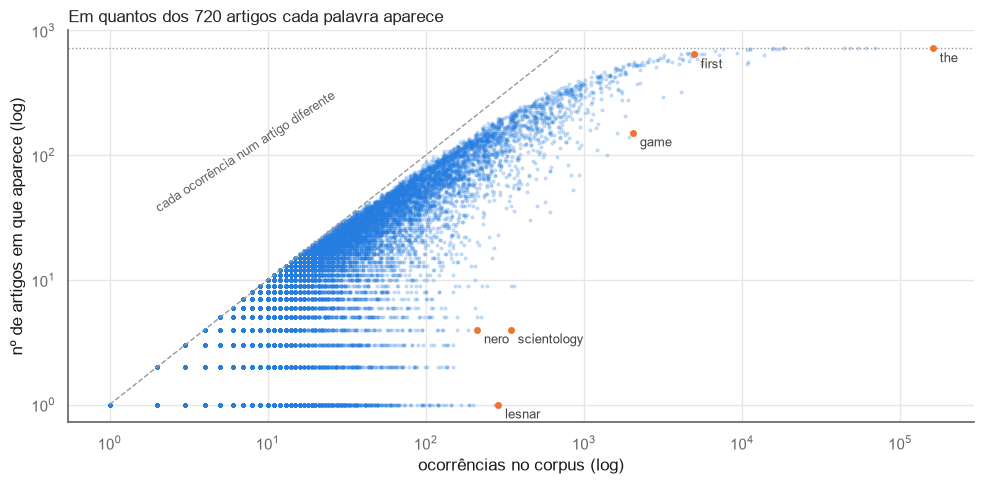

60% das palavras aparecem em 1 artigo só · 8 aparecem em todos os 720


In [24]:
espalhamento = pd.DataFrame({
    "ocorrencias": freq,
    "artigos": palavras.drop_duplicates(["split", "artigo_id", "palavra"])["palavra"].value_counts(),
})
n_artigos = len(artigos)

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(espalhamento["ocorrencias"], espalhamento["artigos"], s=4, alpha=0.2, color=AZUL, rasterized=True)
x = np.array([1, n_artigos])
ax.plot(x, x, color="#999999", linestyle="--", linewidth=1)
ax.axhline(n_artigos, color="#999999", linestyle=":", linewidth=1)
ax.annotate("cada ocorrência num artigo diferente", (30, 30), xytext=(-4, 6), textcoords="offset points",
            rotation=33, fontsize=9, color="#666666", ha="right")
for palavra in ["the", "first", "game", "lesnar", "scientology", "nero"]:
    o, a = espalhamento.loc[palavra]
    ax.plot(o, a, "o", color=CORES["validation"], markersize=4)
    ax.annotate(palavra, (o, a), xytext=(5, -10), textcoords="offset points", fontsize=9, color="#444444")
ax.set(xscale="log", yscale="log", xlabel="ocorrências no corpus (log)", ylabel="nº de artigos em que aparece (log)")
ax.set_title(f"Em quantos dos {n_artigos} artigos cada palavra aparece", loc="left")
plt.tight_layout()
plt.show()

um = espalhamento["artigos"] == 1
print(f"{um.mean():.0%} das palavras aparecem em 1 artigo só · {(espalhamento['artigos'] == n_artigos).sum()} aparecem em todos os {n_artigos}")